# Optimización por Colonias de Hormigas (*Ant System*) en SageMath

**Artículo de referencia:** A. Colorni, M. Dorigo y V. Maniezzo (1991/1992), *"Distributed Optimization by Ant Colonies"*, Proceedings of ECAL91 — European Conference on Artificial Life, París, Elsevier, pp. 134–142.

**Objetivo de este cuaderno:**  
Traducir fielmente el marco matemático y el pseudocódigo del artículo original a una implementación modular, reproducible y visualmente clara en **SageMath**, siguiendo exactamente la estructura de la memoria del proyecto:

1. **Instancias de prueba del TSP** (cuadrícula regular $4\times 4$, instancia de 10 ciudades tipo CCAO, benchmark clásico **Oliver30** de 30 ciudades y grafos aleatorios).
2. **Estructuras de datos en SageMath** (`matrix(RDF, ...)`, `Graph()`, listas tabú) y control de errores numéricos.
3. **Regla de transición probabilística** (Ec. 2) con estabilización logarítmica (*log-sum-exp*) y ruleta ponderada.
4. **Las tres variantes del artículo:** `ANT-quantity`, `ANT-density` y `ANT-cycle`.
5. **Visualización del comportamiento emergente:** evolución de los rastros de feromona hasta cristalizar en un ciclo mínimo.
6. **Batería de experimentos y contraste con el artículo:** comparativa entre variantes, sensibilidad de parámetros ($\alpha, \beta, \rho, Q_h$), eficiencia por número de hormigas (réplica de Figs. 5 y 8) y escalabilidad computacional.
7. **Extensión y demostración en vivo:** mejora con elitismo + búsqueda local *2-opt* y panel interactivo `@interact`.

Todas las celdas están diseñadas para ejecutarse secuencialmente con **semillas fijas** (`set_random_seed`), garantizando que las gráficas y tablas coinciden con los resultados de la memoria.

In [1]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO Y CONSTANTES NUMÉRICAS
# ==============================================================================
import math
import random
import time
import numpy as np

# Constantes de seguridad numérica en float nativo (evita coerción desde RealNumber de Sage)
EPSILON = float(1e-12) # Evita divisiones por cero si dos ciudades coinciden (d_ij = 0)
TAU_MIN = float(1e-15) # Evita que la evaporación lleve tau_ij exactamente a 0.0 (underflow en log)

def fijar_semilla(semilla=42):
    '''
    Fija tanto la semilla interna de SageMath como la del módulo random de Python
    para garantizar reproducibilidad exacta en todas las simulaciones.
    '''
    set_random_seed(int(semilla))
    random.seed(int(semilla))

fijar_semilla(42)
print("Entorno SageMath inicializado correctamente.")

Entorno SageMath inicializado correctamente.


---
## 1. Instancias de prueba del Problema del Viajante (TSP)
*(Correspondencia con la memoria: Secciones 2 y 4)*

El **TSP euclidiano** se define sobre un grafo completo no dirigido y ponderado $G = (V, E)$, donde cada vértice $i \in \{0, \dots, n-1\}$ representa una ciudad con coordenadas $(x_i, y_i) \in \mathbb{R}^2$ y cada arista $(i, j)$ tiene peso igual a la distancia euclidiana:
$$d_{ij} = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}$$

El objetivo es hallar un **ciclo hamiltoniano de longitud mínima** que visite cada ciudad exactamente una vez y regrese al origen.

Implementamos las cuatro familias de instancias contempladas en el diseño experimental:
1. **Cuadrícula regular $4 \times 4$ ($n=16$):** utilizada en las Figs. 5 y 8 del artículo. Su óptimo conocido es exactamente **$L^* = 16.0$** (distancia unidad entre vecinos ortogonales).
2. **Instancia de 10 ciudades (geometría tipo Fig. 2 / CCAO):** problema pequeño cóncavo ideal para pruebas rápidas de sensibilidad.
3. **Benchmark Oliver30 ($n=30$):** instancia exacta de 30 ciudades utilizada en las Figs. 3, 4 y 6 del artículo (procedente de Oliver et al. / Whitley et al. [12]). En el artículo se reportan dos referencias clave:
   - Solución típica de `ANT-density` / algoritmos genéticos previos (Fig. 4): **$424.635$** (entera: **$421$**).
   - Nuevo óptimo encontrado por `ANT-cycle` (Fig. 6): **$423.741$** (entera: **$420$**).
4. **Grafos aleatorios euclidianos:** generados en $[0, 100]^2$ para evaluar tiempos de ejecución y escalabilidad.

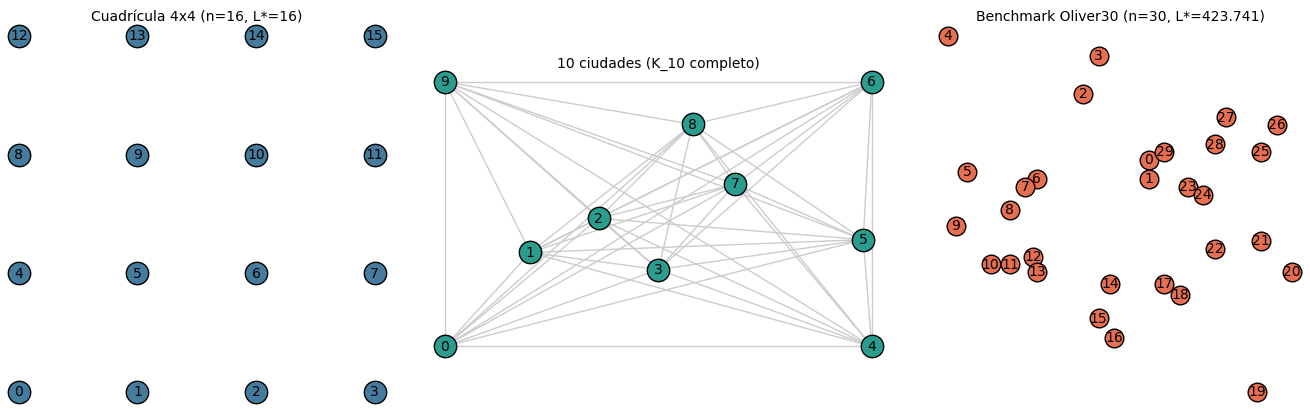

In [2]:
# ==============================================================================
# 1. DEFINICIÓN DE INSTANCIAS BENCHMARK Y REPRESENTACIÓN CON Graph()
# ==============================================================================

def generar_cuadricula_4x4():
    '''Cuadrícula regular 4x4 (16 ciudades, óptimo conocido L* = 16.0).'''
    return [(float(x), float(y)) for y in range(4) for x in range(4)]

def generar_10_ciudades_fig2():
    '''Instancia de 10 ciudades con geometría inspirada en la Fig. 2 (CCAO).'''
    return [
        (0.0, 0.0), (20.0, 22.0), (36.0, 30.0), (50.0, 18.0), (100.0, 0.0),
        (98.0, 25.0), (100.0, 62.0), (68.0, 38.0), (58.0, 52.0), (0.0, 62.0)
    ]

def generar_oliver30():
    '''
    Coordenadas exactas del benchmark Oliver30 (30 ciudades, orden de Dorigo).
    Óptimo real conocido: 423.741 (con distancias redondeadas a entero: 420).
    '''
    return [
        (54.0, 67.0), (54.0, 62.0), (37.0, 84.0), (41.0, 94.0), (2.0, 99.0),
        (7.0, 64.0),  (25.0, 62.0), (22.0, 60.0), (18.0, 54.0), (4.0, 50.0),
        (13.0, 40.0), (18.0, 40.0), (24.0, 42.0), (25.0, 38.0), (44.0, 35.0),
        (41.0, 26.0), (45.0, 21.0), (58.0, 35.0), (62.0, 32.0), (82.0, 7.0),
        (91.0, 38.0), (83.0, 46.0), (71.0, 44.0), (64.0, 60.0), (68.0, 58.0),
        (83.0, 69.0), (87.0, 76.0), (74.0, 78.0), (71.0, 71.0), (58.0, 69.0)
    ]

def generar_grafo_aleatorio(n, lado=100.0, semilla=42):
    '''Genera n ciudades aleatorias uniformemente distribuidas en [0, lado]^2.'''
    fijar_semilla(semilla)
    return [(random.uniform(0.0, lado), random.uniform(0.0, lado)) for _ in range(n)]

def construir_grafo_sage(coords, tour=None, completo=False):
    '''
    Construye un objeto Graph() de SageMath con las posiciones geométricas
    de las ciudades. Si se proporciona un tour, añade únicamente sus aristas;
    si completo=True, añade todas las aristas del grafo completo K_n.
    '''
    n = len(coords)
    G = Graph()
    G.add_vertices(range(n))
    pos = {i: coords[i] for i in range(n)}
    if completo:
        for i in range(n):
            for j in range(i + 1, n):
                d = math.hypot(coords[i][0] - coords[j][0], coords[i][1] - coords[j][1])
                G.add_edge(i, j, round(d, 2))
    elif tour is not None:
        for idx in range(len(tour)):
            u = tour[idx]
            v = tour[(idx + 1) % len(tour)]
            d = math.hypot(coords[u][0] - coords[v][0], coords[u][1] - coords[v][1])
            G.add_edge(u, v, round(d, 2))
    return G, pos

# Creamos las instancias principales
coords_grid = generar_cuadricula_4x4()
coords_10   = generar_10_ciudades_fig2()
coords_o30  = generar_oliver30()

# Visualizamos las tres instancias de referencia usando Graph() de SageMath
G_grid, pos_grid = construir_grafo_sage(coords_grid, completo=False)
G_10,   pos_10   = construir_grafo_sage(coords_10, completo=True)
G_o30,  pos_o30  = construir_grafo_sage(coords_o30, completo=False)

p1 = G_grid.plot(pos=pos_grid, vertex_size=260, vertex_color='#457b9d',
                 title='Cuadrícula 4x4 (n=16, L*=16)')
p2 = G_10.plot(pos=pos_10, vertex_size=260, vertex_color='#2a9d8f',
               edge_color='#cccccc', title='10 ciudades (K_10 completo)')
p3 = G_o30.plot(pos=pos_o30, vertex_size=180, vertex_color='#e76f51',
                title='Benchmark Oliver30 (n=30, L*=423.741)')

graphics_array([p1, p2, p3]).show(figsize=[14, 4.2])

---
## 2. Estructuras de datos: relación Teoría–Código en SageMath
*(Correspondencia con la memoria: Sección 3)*

Para mantener la máxima fidelidad matemática y eficiencia en SageMath, representamos las estructuras del artículo mediante objetos nativos sobre el cuerpo de reales de doble precisión **`RDF`** (*Real Double Field*):

| Elemento teórico del artículo | Notación | Objeto en SageMath / Python | Detalle de diseño |
| :--- | :---: | :--- | :--- |
| Matriz de distancias euclidianas | $D = (d_{ij})$ | `matrix(RDF, n, n)` | Simétrica, diagonal nula ($d_{ii} = 0$). |
| Matriz de visibilidad heurística | $\eta = (\eta_{ij})$ | `matrix(RDF, n, n)` | $\eta_{ij} = 1 / \max(d_{ij}, \varepsilon)$ para $i \neq j$; $\eta_{ii} = 0$. |
| Matriz de intensidad de feromona | $\tau(t) = (\tau_{ij}(t))$ | `matrix(RDF, n, n)` | Inicializada a $\tau_0 > 0$ (valor pequeño uniforme) fuera de la diagonal. |
| Lista tabú de la hormiga $k$ | $\text{tabu}_k$ | `list` (orden del tour) + `set` (nodos pendientes) | Garantiza visitas únicas en tiempo $O(1)$ de comprobación. |
| Representación topológica | $G = (V, E)$ | `Graph()` de SageMath | Visualización de grafos completos y ciclos hamiltonianos. |

> **Control de división por cero:** Si dos ciudades tuvieran coordenadas idénticas ($d_{ij} = 0$), el cálculo directo $1/d_{ij}$ lanzaría `ZeroDivisionError`. Acotar el denominador con `max(d, EPSILON)` evita fallos sin alterar distancias reales positivas.

In [3]:
# ==============================================================================
# 2. MATRICES DE DISTANCIA, VISIBILIDAD Y FEROMONAS EN SAGEMATH (RDF)
# ==============================================================================

def construir_matrices_tsp(coords, tau0=0.1):
    '''
    Construye las tres matrices fundamentales del Ant System como arrays NumPy float64
    para acelerar el bucle interno:
      - D   : matriz de distancias euclidianas d_ij
      - eta : matriz de visibilidad heurística eta_ij = 1 / d_ij (controlando d_ij = 0)
      - tau : matriz de intensidad de feromona inicializada a tau0 (0 en la diagonal)
    '''
    n = len(coords)
    tau0_f = float(tau0)
    eps_f = float(EPSILON)

    D   = np.zeros((n, n), dtype=np.float64)
    eta = np.zeros((n, n), dtype=np.float64)
    tau = np.zeros((n, n), dtype=np.float64)

    for i in range(n):
        xi, yi = coords[i]
        for j in range(i + 1, n):
            xj, yj = coords[j]
            d = math.hypot(xi - xj, yi - yj)
            D[i, j] = D[j, i] = d
            # Control explícito de división por cero si existen nodos coincidentes
            d_seguro = d if d > eps_f else eps_f
            eta[i, j] = eta[j, i] = 1.0 / d_seguro
            tau[i, j] = tau[j, i] = tau0_f

    return D, eta, tau

def longitud_tour(tour, D, redondeo_entero=False):
    '''
    Calcula la longitud total de un ciclo hamiltoniano cerrado (incluyendo
    la arista de regreso desde la última ciudad a la ciudad inicial).
    Si redondeo_entero=True, redondea cada arista al entero más cercano
    (criterio "integer length" usado en el artículo de Colorni et al., 1991).
    '''
    n = len(tour)
    total = 0.0
    for idx in range(n):
        u = tour[idx]
        v = tour[(idx + 1) % n]
        d = float(D[u, v])
        total += round(d) if redondeo_entero else d
    return total

# --- Verificación rápida sobre Oliver30 ---
D_o30, eta_o30, tau_o30 = construir_matrices_tsp(coords_o30, tau0=0.1)

# Tour óptimo reportado en la Fig. 6 del artículo (indexación 0-based)
tour_optimo_o30 = [c - 1 for c in [
    1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,
    17, 18, 19, 20, 21, 22, 23, 25, 24, 26, 27, 28, 29, 30, 2
]]
# Tour secuencial de la Fig. 4 del artículo
tour_fig4_o30 = list(range(30))

print("Submatriz 4x4 de distancias D (Oliver30):")
print(matrix(RDF, D_o30[:4, :4]).n(digits=4))
print(f"\nVerificación Fig. 4 del artículo -> Real: {longitud_tour(tour_fig4_o30, D_o30):.3f} | Entera: {int(longitud_tour(tour_fig4_o30, D_o30, True))}  (Paper: 424.635 / 421)")
print(f"Verificación Fig. 6 del artículo -> Real: {longitud_tour(tour_optimo_o30, D_o30):.3f} | Entera: {int(longitud_tour(tour_optimo_o30, D_o30, True))}  (Paper: 423.741 / 420)")

Submatriz 4x4 de distancias D (Oliver30):


TypeError: numpy matrix must be either c_contiguous or f_contiguous

---
## 3. Regla de transición probabilística y control numérico
*(Correspondencia con la memoria: Secciones 2 y 3)*

Cuando la hormiga $k$ se encuentra en la ciudad $i$ en el instante $t$, elige la siguiente ciudad $j$ entre el conjunto de ciudades **aún no visitadas** ($J_k = V \setminus \text{tabu}_k$) con probabilidad dada por la **Ecuación (2)** del artículo:

$$P_{ij}^{k}(t) = \frac{[\tau_{ij}(t)]^{\alpha} \cdot [\eta_{ij}]^{\beta}}{\displaystyle\sum_{l \in J_k} [\tau_{il}(t)]^{\alpha} \cdot [\eta_{il}]^{\beta}}$$

- **$\alpha \ge 0$ (sensibilidad al rastro):** controla el peso de la memoria colectiva (feromonas). Con $\alpha = 0$, el algoritmo se reduce a una heurística voraz (*greedy*) estocástica.
- **$\beta \ge 0$ (sensibilidad a la distancia):** controla el peso de la visibilidad heurística $\eta_{ij} = 1/d_{ij}$. Con $\beta = 0$, las hormigas ignoran las distancias y solo siguen feromonas.

### Estabilidad numérica (*truco log-sum-exp*)
Si $\alpha$ o $\beta$ son grandes (por ejemplo $\beta = 10$ en las pruebas de sensibilidad del artículo) o si $\tau_{ij}$ se evapora hasta valores muy pequeños, evaluar directamente $\tau_{ij}^\alpha \cdot \eta_{ij}^\beta$ puede provocar ***overflow*** (`inf`) o ***underflow*** (`0.0`, generando `0/0 = NaN`).

Para evitarlo manteniendo **exactitud matemática**, trabajamos en espacio logarítmico:
$$\ell_j = \alpha \ln(\tau_{ij}) + \beta \ln(\eta_{ij}), \qquad M = \max_{l \in J_k} \ell_l, \qquad w_j = e^{\ell_j - M} \in (0, 1]$$
Así el mayor peso es exactamente $1$, nunca hay *overflow*, la suma es estrictamente positiva y la distribución $P_{ij} = w_j / \sum_{l \in J_k} w_l$ es algebraicamente idéntica a la Ecuación (2). Finalmente, el muestreo se realiza por **ruleta ponderada**.

In [4]:
# ==============================================================================
# 3. REGLA DE TRANSICIÓN PROBABILÍSTICA (EC. 2) Y RULETA PONDERADA
# ==============================================================================

def calcular_probabilidades_transicion(ciudad_actual, no_visitadas, tau, eta, alpha, beta):
    '''
    Calcula la distribución de probabilidad P_ij (Ec. 2) sobre las ciudades
    no visitadas aplicando estabilización logarítmica (log-sum-exp).
    Compatible tanto con arrays NumPy float64 como con matrix(RDF, ...).
    '''
    candidatas = list(no_visitadas)
    if len(candidatas) == 1:
        return candidatas, [1.0]

    alpha_f = float(alpha)
    beta_f = float(beta)
    tau_min_f = float(TAU_MIN)
    eps_f = float(EPSILON)

    log_pesos = []
    for j in candidatas:
        lw = 0.0
        if alpha_f != 0.0:
            t_val = tau[ciudad_actual, j]
            if t_val < tau_min_f:
                t_val = tau_min_f
            lw += alpha_f * math.log(t_val)
        if beta_f != 0.0:
            e_val = eta[ciudad_actual, j]
            if e_val < eps_f:
                e_val = eps_f
            lw += beta_f * math.log(e_val)
        log_pesos.append(lw)

    # Desplazamiento por el máximo para impedir overflow/underflow
    max_lw = max(log_pesos)
    pesos = [math.exp(lw - max_lw) for lw in log_pesos]
    suma_pesos = sum(pesos)

    # Respaldo defensivo en caso extremo no finito
    if not math.isfinite(suma_pesos) or suma_pesos <= 0.0:
        prob_uniforme = 1.0 / len(candidatas)
        return candidatas, [prob_uniforme] * len(candidatas)

    probs = [w / suma_pesos for w in pesos]
    return candidatas, probs


def ruleta_ponderada(candidatas, probs):
    '''
    Selección estocástica mediante el método de la ruleta ponderada.
    '''
    r = random.random()
    acumulado = 0.0
    for ciudad, p in zip(candidatas, probs):
        acumulado += p
        if r <= acumulado:
            return ciudad
    return candidatas[-1]

def elegir_siguiente_ciudad(ciudad_actual, no_visitadas, tau, eta, alpha, beta):
    '''Combina el cálculo de P_ij y la selección por ruleta ponderada.'''
    candidatas, probs = calcular_probabilidades_transicion(
        ciudad_actual, no_visitadas, tau, eta, alpha, beta
    )
    return ruleta_ponderada(candidatas, probs)

# --- Prueba didáctica de estabilidad numérica ---
D_10, eta_10, tau_10 = construir_matrices_tsp(coords_10, tau0=1e-12)
cands, probs_ext = calcular_probabilidades_transicion(
    0, set(range(1, 10)), tau_10, eta_10, alpha=10.0, beta=10.0
)
print("Prueba extrema (tau_0 = 1e-12, alpha = 10, beta = 10) desde ciudad 0:")
print(f"  Suma de probabilidades = {sum(probs_ext):.12f} (sin NaN ni overflow)")
print("  Top-3 ciudades más probables:",
      sorted(zip(cands, [round(p, 4) for p in probs_ext]), key=lambda x: -x[1])[:3])

Prueba extrema (tau_0 = 1e-12, alpha = 10, beta = 10) desde ciudad 0:
  Suma de probabilidades = 1.000000000000 (sin NaN ni overflow)
  Top-3 ciudades más probables: [(1, 0.9858), (2, 0.0104), (3, 0.003)]


---
## 4. Implementación de las tres variantes: `ANT-quantity`, `ANT-density` y `ANT-cycle`
*(Correspondencia con la memoria: Secciones 2 y 3; Artículo: Secciones 4 y 5)*

Todas las variantes comparten la ecuación de actualización y evaporación de feromonas:
$$\tau_{ij}(t_{\text{nuevo}}) = \rho \cdot \tau_{ij}(t) + \Delta \tau_{ij}, \qquad \Delta \tau_{ij} = \sum_{k=1}^{m} \Delta \tau_{ij}^{k}$$

> **Detalle clave de notación (¡excelente punto para comentar en la exposición!):**  
> En el artículo original de Colorni, Dorigo y Maniezzo (1991), $\rho \in (0, 1)$ multiplica directamente a $\tau_{ij}(t)$, por lo que **$\rho$ representa el factor de persistencia** (y $1 - \rho$ la fracción que se evapora). Así, el valor recomendado $\rho = 0.7$ significa que persiste el $70\%$ del rastro previo y se evapora el $30\%$. En publicaciones posteriores de ACO es habitual escribir $(1-\rho)\tau_{ij}$. Aquí seguimos **exactamente** la Ecuación (1) del artículo de 1991.

Las tres variantes difieren en **cuándo** se actualiza $\tau$ y **cuánta** feromona deposita cada hormiga $k$:

| Variante | Momento de actualización | Depósito $\Delta \tau_{ij}^{k}$ | Información usada |
| :--- | :--- | :---: | :--- |
| **`ANT-quantity`** (Ec. 3) | **Paso a paso** (tras cada salto $t \to t+1$) | $Q_1 / d_{ij}$ | Local (longitud de la arista) |
| **`ANT-density`** (Ec. 4) | **Paso a paso** (tras cada salto $t \to t+1$) | $Q_2$ | Local (constante, independiente de $d_{ij}$) |
| **`ANT-cycle`** (Ec. 5 y 1') | **Al final de cada ciclo completo** ($t \to t+n$) | $Q_3 / L_k$ | **Global** (calidad total $L_k$ del recorrido) |

Como el TSP euclidiano es **simétrico** ($d_{ij} = d_{ji}$), el depósito sobre una arista usada $(u, v)$ se aplica simétricamente a $\tau_{uv}$ y $\tau_{vu}$. Además, cada hormiga realiza exactamente $n$ desplazamientos por ciclo ($n-1$ ciudades nuevas + cierre del ciclo hacia su ciudad de origen).

In [5]:
# ==============================================================================
# 4. MOTOR UNIFICADO DEL ANT SYSTEM (ANT-QUANTITY, ANT-DENSITY, ANT-CYCLE)
# ==============================================================================

def busqueda_local_2opt(tour, D):
    '''
    Mejora local 2-opt (usada opcionalmente en la Sección 10: extensiones).
    Elimina cruces de aristas invirtiendo subsegmentos del recorrido mientras
    se reduzca la longitud total.
    '''
    mejor = list(tour)
    n = len(mejor)
    mejoro = True
    while mejoro:
        mejoro = False
        for i in range(n - 1):
            a, b = mejor[i], mejor[i + 1]
            for j in range(i + 2, n):
                if i == 0 and j == n - 1:
                    continue
                c, d = mejor[j], mejor[(j + 1) % n]
                ganancia = (float(D[a, c]) + float(D[b, d])) - (float(D[a, b]) + float(D[c, d]))
                if ganancia < -1e-9:
                    mejor[i + 1:j + 1] = reversed(mejor[i + 1:j + 1])
                    mejoro = True
    return mejor



def ejecutar_ant_system(
    coords,
    variante="ant-cycle",
    n_hormigas=None,
    n_ciclos=100,
    alpha=1.0,
    beta=5.0,
    rho=0.7,
    Q=100.0,
    tau0=0.1,
    semilla=42,
    ciclos_captura=None,
    objetivo_optimo=None,
    elitismo=0.0,
    usar_2opt=False
):
    '''
    Ejecuta una simulación completa de Ant System sobre las coordenadas dadas.
    Utiliza arrays NumPy float64 en el bucle interno y devuelve matrices nativas
    matrix(RDF, ...) en 'tau_final', 'D' y 'snapshots_tau' para mantener
    compatibilidad total con las funciones de visualización en SageMath.
    '''
    variante = variante.lower().strip()
    if variante not in ("ant-quantity", "ant-density", "ant-cycle"):
        raise ValueError("Variante no válida. Usa 'ant-quantity', 'ant-density' o 'ant-cycle'.")

    t_inicio = time.perf_counter()
    fijar_semilla(semilla)

    # Conversión única a float nativo para evitar sobrecarga del preparser de SageMath
    alpha_f    = float(alpha)
    beta_f     = float(beta)
    rho_f      = float(rho)
    Q_f        = float(Q)
    tau0_f     = float(tau0)
    elitismo_f = float(elitismo)
    eps_f      = float(EPSILON)
    tau_min_f  = float(TAU_MIN)
    obj_f      = float(objetivo_optimo) if objetivo_optimo is not None else None

    n = len(coords)
    m = n if n_hormigas is None else int(n_hormigas)
    D, eta, tau = construir_matrices_tsp(coords, tau0=tau0_f)

    # Preasignación única de la matriz de depósitos (se limpia con .fill(0.0))
    delta_tau = np.zeros((n, n), dtype=np.float64)

    capturas_set = set(ciclos_captura) if ciclos_captura is not None else set()
    snapshots_tau = {}

    mejor_tour_global = None
    mejor_long_global = float('inf')
    ciclo_optimo = None

    hist_mejor_global = []
    hist_mejor_ciclo  = []
    hist_media_ciclo  = []
    hist_std_ciclo    = []

    # ------------------------------------------------------------------
    # BUCLE PRINCIPAL DE CICLOS (Paso 2 del pseudocódigo del artículo)
    # ------------------------------------------------------------------
    for ciclo in range(1, int(n_ciclos) + 1):

        # Posicionamiento inicial de las m hormigas (b_i(t) repartidas entre ciudades)
        ciudades_inicio = [k % n for k in range(m)]
        random.shuffle(ciudades_inicio)

        rutas = [[c] for c in ciudades_inicio]              # Lista tabú ordenada
        no_visitadas = [set(range(n)) - {c} for c in ciudades_inicio]

        # --------------------------------------------------------------
        # A) VARIANTES PASO A PASO: ANT-quantity y ANT-density (Sec. 4)
        # --------------------------------------------------------------
        if variante in ("ant-quantity", "ant-density"):
            for paso in range(n):
                delta_tau.fill(0.0)
                for k in range(m):
                    u = rutas[k][-1]
                    if paso < n - 1:
                        v = elegir_siguiente_ciudad(u, no_visitadas[k], tau, eta, alpha_f, beta_f)
                        rutas[k].append(v)
                        no_visitadas[k].remove(v)
                    else:
                        # n-ésimo paso: regreso a la ciudad de origen cerrando el ciclo
                        v = rutas[k][0]

                    if variante == "ant-quantity":
                        d_uv = D[u, v]
                        deposito = Q_f / (d_uv if d_uv > eps_f else eps_f)
                    else:  # ant-density
                        deposito = Q_f

                    delta_tau[u, v] += deposito
                    delta_tau[v, u] += deposito

                # Actualización vectorizada paso a paso: Ecuación (1)
                tau = np.maximum(rho_f * tau + delta_tau, tau_min_f)
                np.fill_diagonal(tau, 0.0)

        # --------------------------------------------------------------
        # B) VARIANTE POR CICLO COMPLETO: ANT-cycle (Sec. 5)
        # --------------------------------------------------------------
        else:
            for k in range(m):
                for _ in range(n - 1):
                    u = rutas[k][-1]
                    v = elegir_siguiente_ciudad(u, no_visitadas[k], tau, eta, alpha_f, beta_f)
                    rutas[k].append(v)
                    no_visitadas[k].remove(v)

        # Evaluación de los m recorridos completos del ciclo
        longitudes = []
        for k in range(m):
            if usar_2opt:
                rutas[k] = busqueda_local_2opt(rutas[k], D)
            L_k = longitud_tour(rutas[k], D, redondeo_entero=False)
            longitudes.append(L_k)

            if L_k < mejor_long_global:
                mejor_long_global = L_k
                mejor_tour_global = list(rutas[k])
                if obj_f is not None and ciclo_optimo is None:
                    if mejor_long_global <= obj_f + 1e-6:
                        ciclo_optimo = ciclo

        # En ANT-cycle actualizamos feromonas una vez concluidos los m tours (Ec. 5 y 1')
        if variante == "ant-cycle":
            delta_tau.fill(0.0)
            for k in range(m):
                L_k = longitudes[k]
                deposito = Q_f / (L_k if L_k > eps_f else eps_f)
                tour_k = rutas[k]
                for idx in range(n):
                    u = tour_k[idx]
                    v = tour_k[(idx + 1) % n]
                    delta_tau[u, v] += deposito
                    delta_tau[v, u] += deposito

            # Refuerzo elitista opcional (solo activo en la Sección 10)
            if elitismo_f > 0.0 and mejor_tour_global is not None:
                L_best = mejor_long_global
                dep_elite = elitismo_f * (Q_f / (L_best if L_best > eps_f else eps_f))
                for idx in range(n):
                    u = mejor_tour_global[idx]
                    v = mejor_tour_global[(idx + 1) % n]
                    delta_tau[u, v] += dep_elite
                    delta_tau[v, u] += dep_elite

            # Actualización vectorizada al cierre del ciclo: Ecuación (1')
            tau = np.maximum(rho_f * tau + delta_tau, tau_min_f)
            np.fill_diagonal(tau, 0.0)

        # Registro de estadísticas del ciclo
        media = sum(longitudes) / float(m)
        var = sum((x - media) ** 2 for x in longitudes) / float(m)
        hist_mejor_global.append(mejor_long_global)
        hist_mejor_ciclo.append(min(longitudes))
        hist_media_ciclo.append(media)
        hist_std_ciclo.append(math.sqrt(var))

        if ciclo in capturas_set:
            snapshots_tau[ciclo] = matrix(RDF, tau)

    tiempo_total = time.perf_counter() - t_inicio
    return {
        "variante": variante,
        "mejor_tour": mejor_tour_global,
        "mejor_longitud": mejor_long_global,
        "mejor_longitud_entera": int(longitud_tour(mejor_tour_global, D, redondeo_entero=True)),
        "ciclo_optimo": ciclo_optimo,
        "hist_mejor_global": hist_mejor_global,
        "hist_mejor_ciclo": hist_mejor_ciclo,
        "hist_media_ciclo": hist_media_ciclo,
        "hist_std_ciclo": hist_std_ciclo,
        "tau_final": matrix(RDF, tau),
        "snapshots_tau": snapshots_tau,
        "D": matrix(RDF, D),
        "tiempo_s": tiempo_total
    }

print("Motor del Ant System cargado correctamente.")

Motor del Ant System cargado correctamente.


---
## 5. Visualización del comportamiento emergente: cristalización de las feromonas
*(Enfoque clave del enunciado: mostrar el comportamiento emergente de una colonia simulada)*

Antes de entrar en tablas numéricas, esta sección hace visible el corazón del algoritmo bioinspirado (**estigmergia y autocatálisis**):
- En el **ciclo 1**, la feromona está repartida de forma difusa por multitud de aristas del grafo porque las hormigas exploran rutas variadas.
- A medida que avanzan los ciclos, las aristas pertenecientes a recorridos cortos reciben mayor depósito ($Q_3 / L_k$) y sobreviven mejor a la evaporación ($\rho \cdot \tau_{ij}$).
- El bucle de retroalimentación positiva hace que la colonia **cristalice de forma colectiva sobre un ciclo hamiltoniano mínimo**, sin que exista ningún controlador central.

> **Nota para la exposición:** Esta figura en 4 fotogramas es el mejor recurso visual para explicar en 30 segundos qué significa "comportamiento emergente".

Cuadrícula 4x4 (ANT-cycle, alpha=1, beta=1):
  Mejor longitud encontrada : 16.0000 (Óptimo conocido = 16.0)
  Primer ciclo en el óptimo : 31
  Tiempo de ejecución       : 3.128 s


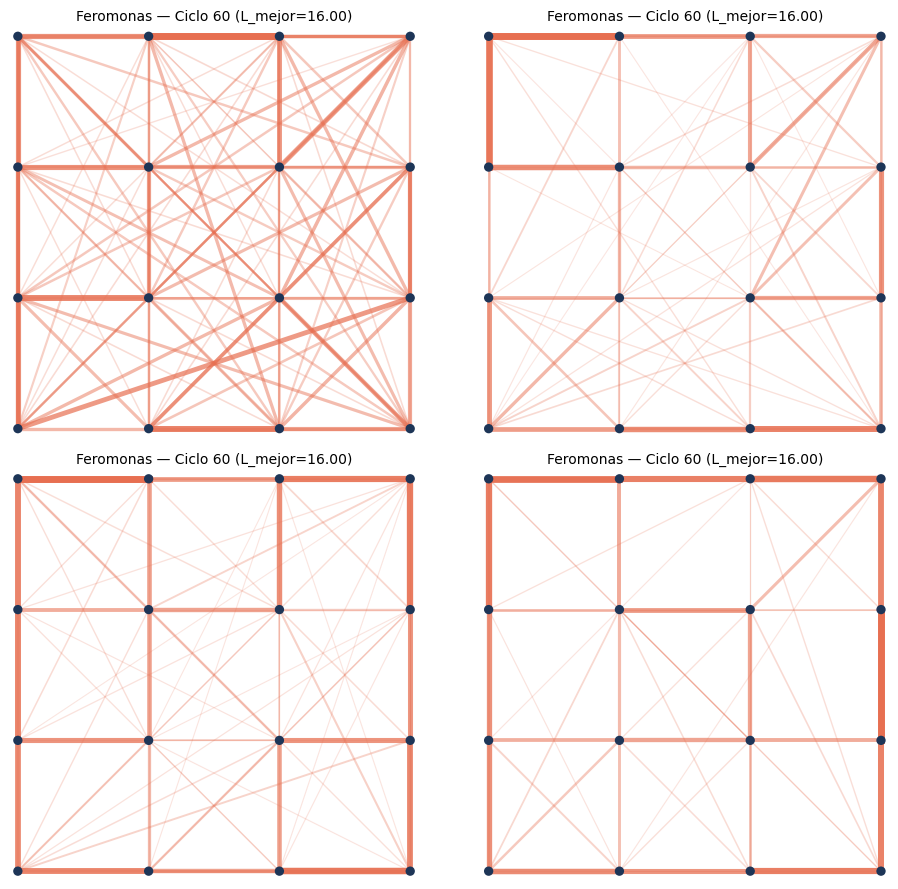

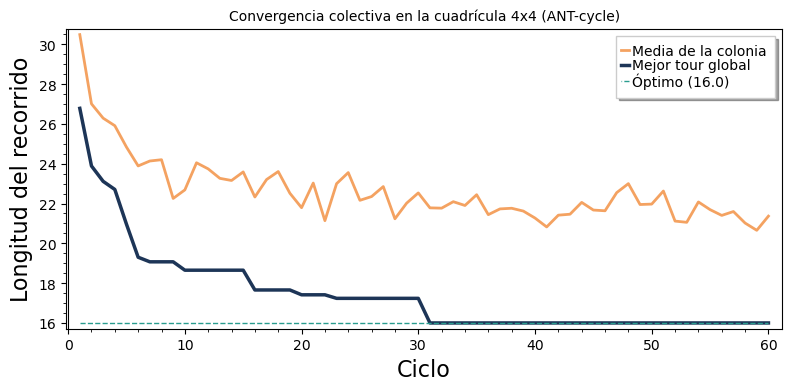

In [6]:
# ==============================================================================
# 5. VISUALIZACIÓN DE RASTROS DE FEROMONA Y RUTAS ÓPTIMAS EN SAGEMATH
# ==============================================================================

def dibujar_mapa_feromonas(coords, tau, titulo="", tour_resaltado=None, umbral_rel=0.05):
    '''
    Dibuja la matriz de feromonas tau usando primitivas gráficas 2D nativas de SageMath:
    el grosor y la opacidad de cada arista son proporcionales a su intensidad relativa
    tau_ij / tau_max. Opcionalmente superpone un tour resaltado.
    '''
    n = len(coords)
    g = Graphics()

    # Buscamos la feromona máxima fuera de la diagonal para normalizar visualmente
    tau_max = max(float(tau[i, j]) for i in range(n) for j in range(i + 1, n))
    if tau_max <= 0.0:
        tau_max = 1.0

    # Dibujamos las aristas con intensidad significativa
    for i in range(n):
        for j in range(i + 1, n):
            intensidad = float(tau[i, j]) / tau_max
            if intensidad >= umbral_rel:
                grosor = 0.5 + 4.5 * intensidad
                opacidad = min(1.0, 0.12 + 0.88 * intensidad)
                g += line([coords[i], coords[j]],
                          color='#e76f51', thickness=grosor, alpha=opacidad)

    # Si se pide resaltar la ruta óptima en línea discontinua azul oscuro
    if tour_resaltado is not None:
        pts_tour = [coords[c] for c in tour_resaltado] + [coords[tour_resaltado[0]]]
        g += line(pts_tour, color='#1d3557', thickness=1.6, linestyle='--')

    # Nodos de las ciudades
    g += points(coords, color='#1d3557', size=45, zorder=5)
    g.axes(False)
    g.set_aspect_ratio(1)
    if titulo:
        # Margen ligero para que el título se vea limpio
        g.SHOW_OPTIONS['title'] = titulo
    return g

def dibujar_ruta_grafo(coords, tour, titulo=""):
    '''Visualiza el ciclo hamiltoniano resultante como un objeto Graph() de SageMath.'''
    G, pos = construir_grafo_sage(coords, tour=tour, completo=False)
    return G.plot(
        pos=pos,
        vertex_size=240,
        vertex_color='#a8dadc',
        edge_color='#1d3557',
        title=titulo
    )

# Ejecutamos ANT-cycle sobre la cuadrícula 4x4 (alpha=1, beta=1 para observar
# con claridad la transición progresiva desde exploración difusa hasta el óptimo L*=16)
ciclos_foto = [1, 10, 25, 60]
res_emergente = ejecutar_ant_system(
    coords_grid,
    variante="ant-cycle",
    n_hormigas=16,
    n_ciclos=60,
    alpha=1.0,
    beta=1.0,
    rho=0.7,
    Q=100.0,
    tau0=0.1,
    semilla=101,
    ciclos_captura=ciclos_foto,
    objetivo_optimo=16.0
)

print(f"Cuadrícula 4x4 (ANT-cycle, alpha=1, beta=1):")
print(f"  Mejor longitud encontrada : {res_emergente['mejor_longitud']:.4f} (Óptimo conocido = 16.0)")
print(f"  Primer ciclo en el óptimo : {res_emergente['ciclo_optimo']}")
print(f"  Tiempo de ejecución       : {res_emergente['tiempo_s']:.3f} s")

# Panel de 4 fotogramas mostrando el comportamiento emergente de las feromonas
paneles = []
for c in ciclos_foto:
    p = dibujar_mapa_feromonas(
        coords_grid,
        res_emergente["snapshots_tau"][c],
        titulo=f"Feromonas — Ciclo {c} (L_mejor={res_emergente['hist_mejor_global'][c-1]:.2f})",
        umbral_rel=0.06
    )
    paneles.append(p)

graphics_array([paneles[:2], paneles[2:]]).show(figsize=[10, 9])

# Mostramos la evolución conjunta de la media de la colonia vs. mejor global
p_med = list_plot(
    list(enumerate(res_emergente["hist_media_ciclo"], start=1)),
    plotjoined=True, color='#f4a261', thickness=2, legend_label='Media de la colonia'
)
p_mej = list_plot(
    list(enumerate(res_emergente["hist_mejor_global"], start=1)),
    plotjoined=True, color='#1d3557', thickness=2.5, legend_label='Mejor tour global'
)
p_opt = line([(1, 16.0), (60, 16.0)], color='#2a9d8f', linestyle='--', legend_label='Óptimo (16.0)')

(p_med + p_mej + p_opt).show(
    frame=True,
    axes_labels=['Ciclo', 'Longitud del recorrido'],
    title='Convergencia colectiva en la cuadrícula 4x4 (ANT-cycle)',
    figsize=[8, 4]
)

---
## 6. Experimento 1: Comparativa entre `ANT-quantity`, `ANT-density` y `ANT-cycle`
*(Correspondencia con la memoria: Sección 5; Artículo: Figs. 3, 4 y 6)*

En el artículo original, los autores concluyen que **`ANT-cycle` supera sistemáticamente a `ANT-quantity` y `ANT-density`** en instancias más exigentes como **Oliver30** ($n=30$). La razón teórica es clara:
- `ANT-quantity` y `ANT-density` refuerzan aristas *a ciegas* paso a paso, sin saber si la ruta completa será buena o mala; esto favorece el estancamiento en mínimos locales.
- `ANT-cycle` espera a que cada hormiga cierre el ciclo para depositar $Q_3 / L_k$, inyectando **retroalimentación global** proporcional a la calidad completa del recorrido.

Replicamos la comparativa en **Oliver30** usando los parámetros de referencia del artículo ($\alpha = 1, \beta = 5, \rho = 0.7, Q = 100, m = 30$).

Variante,Longitud real,Longitud entera,Desviación vs 423.741,Tiempo (s)
ant-quantity,423.912,,+0.04%,41.97
ant-density,434.509,,+2.54%,43.50
ant-cycle,426.544,,+0.66%,44.28


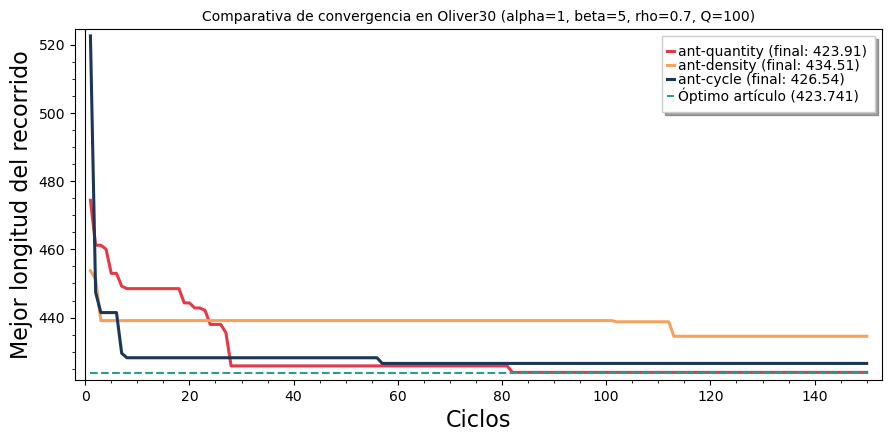

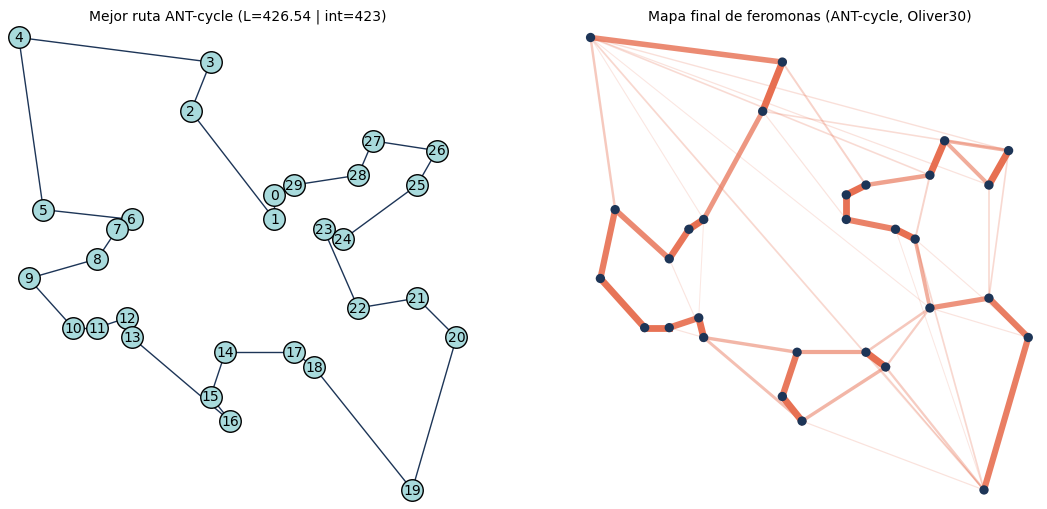

In [7]:
# ==============================================================================
# 6. EXPERIMENTO 1: COMPARATIVA DE LAS 3 VARIANTES EN OLIVER30
# ==============================================================================

N_CICLOS_O30 = 150
variantes = ["ant-quantity", "ant-density", "ant-cycle"]
colores_var = {
    "ant-quantity": "#e63946",
    "ant-density":  "#f4a261",
    "ant-cycle":    "#1d3557"
}

resultados_o30 = {}
filas_tabla = [["Variante", "Longitud real", "Longitud entera", "Desviación vs 423.741", "Tiempo (s)"]]

for var in variantes:
    res = ejecutar_ant_system(
        coords_o30,
        variante=var,
        n_hormigas=30,
        n_ciclos=N_CICLOS_O30,
        alpha=1.0,
        beta=5.0,
        rho=0.7,
        Q=100.0,
        tau0=0.1,
        semilla=42
    )
    resultados_o30[var] = res
    desv_pct = 100.0 * (res["mejor_longitud"] - 423.741) / 423.741
    filas_tabla.append([
        var,
        f"{res['mejor_longitud']:.3f}",
        res["mejor_longitud_entera"],
        f"+{desv_pct:.2f}%",
        f"{res['tiempo_s']:.2f}"
    ])

show(table(filas_tabla, header_row=True, frame=True))

# Gráfica de curvas de convergencia (estilo Fig. 3 del artículo)
g_conv = Graphics()
for var in variantes:
    hist = resultados_o30[var]["hist_mejor_global"]
    g_conv += list_plot(
        list(enumerate(hist, start=1)),
        plotjoined=True,
        color=colores_var[var],
        thickness=2.2,
        legend_label=f"{var} (final: {hist[-1]:.2f})"
    )

g_conv += line([(1, 423.741), (N_CICLOS_O30, 423.741)],
               color='#2a9d8f', linestyle='--', thickness=1.5,
               legend_label='Óptimo artículo (423.741)')

g_conv.show(
    frame=True,
    axes_labels=['Ciclos', 'Mejor longitud del recorrido'],
    title='Comparativa de convergencia en Oliver30 (alpha=1, beta=5, rho=0.7, Q=100)',
    figsize=[9, 4.5]
)

# Visualización lado a lado: mejor ruta de ANT-cycle en Graph() y su mapa de feromonas
res_cyc = resultados_o30["ant-cycle"]
p_ruta = dibujar_ruta_grafo(
    coords_o30,
    res_cyc["mejor_tour"],
    titulo=f"Mejor ruta ANT-cycle (L={res_cyc['mejor_longitud']:.2f} | int={res_cyc['mejor_longitud_entera']})"
)
p_fero = dibujar_mapa_feromonas(
    coords_o30,
    res_cyc["tau_final"],
    titulo="Mapa final de feromonas (ANT-cycle, Oliver30)",
    umbral_rel=0.05
)
graphics_array([p_ruta, p_fero]).show(figsize=[12, 5.2])

---
## 7. Experimento 2: Análisis de sensibilidad de parámetros ($\alpha, \beta, \rho, Q_h$)
*(Correspondencia con la memoria: Sección 4; Artículo: Sección 6)*

Siguiendo la metodología exacta de la Sección 6 del artículo, variamos **un parámetro cada vez** manteniendo constantes los demás respecto a la configuración base de `ANT-cycle` ($\alpha = 1, \beta = 2, \rho = 0.7, Q_3 = 100$) sobre la instancia de 10 ciudades y promediando sobre 5 semillas independientes:

- **$\alpha \in \{0, 0.5, 1, 2, 5\}$:** Valores bajos ($\alpha < 1$) ralentizan la convergencia; valores altos ($\alpha \ge 2$) provocan estancamiento prematuro por exceso de autocatálisis.
- **$\beta \in \{0, 1, 2, 5, 10\}$:** Con $\beta = 0$ el sistema pierde la guía heurística de distancia y empeora drásticamente; valores moderados ($2 \le \beta \le 5$) equilibran exploración y explotación.
- **$\rho \in \{0.3, 0.5, 0.7, 0.9\}$:** Si $\rho$ es muy bajo, la feromona se evapora demasiado rápido (amnesia); si es muy alto, los rastros subóptimos iniciales no se olvidan. El óptimo empírico suele situarse cerca de $\rho \approx 0.7$.
- **$Q_3 \in \{1, 100, 10000\}$:** Como señalan los autores, variar la escala de $Q_3$ apenas altera el resultado en `ANT-cycle` porque afecta proporcionalmente al numerador y denominador de la Ecuación (2).


--- Sensibilidad respecto a 'alpha' (5 repeticiones, n=18) ---


alpha,Media mejor L,Mínimo L,Máximo L,Desv. típ.
,385.07,364.82,419.79,18.72
,343.13,339.36,358.11,7.49
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00
,345.99,339.36,365.26,10.04



--- Sensibilidad respecto a 'beta' (5 repeticiones, n=18) ---


beta,Media mejor L,Mínimo L,Máximo L,Desv. típ.
,630.75,576.68,663.77,31.34
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00



--- Sensibilidad respecto a 'rho' (5 repeticiones, n=18) ---


rho,Media mejor L,Mínimo L,Máximo L,Desv. típ.
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00



--- Sensibilidad respecto a 'Q' (5 repeticiones, n=18) ---


Q,Media mejor L,Mínimo L,Máximo L,Desv. típ.
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00
,339.36,339.36,339.36,0.00


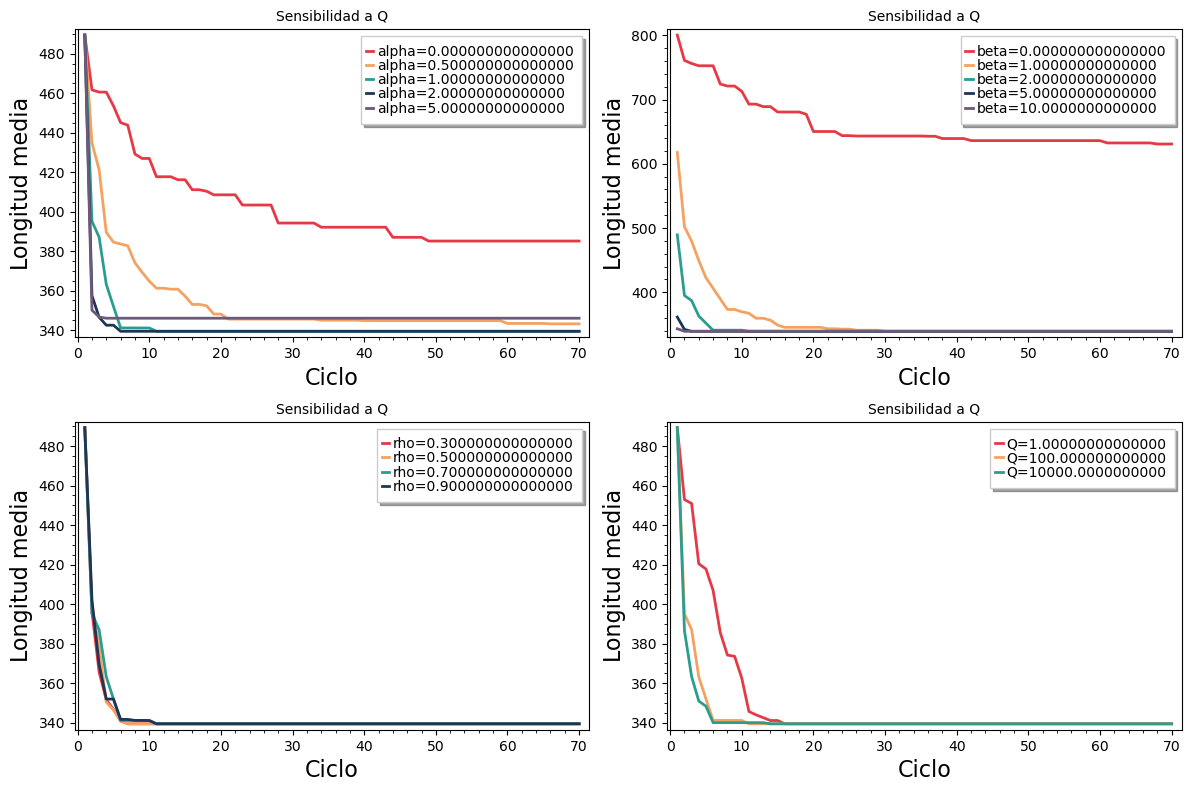

In [8]:
# ==============================================================================
# 7. EXPERIMENTO 2: SENSIBILIDAD DE PARÁMETROS EN ANT-CYCLE
# ==============================================================================

def evaluar_parametro(coords, nombre_param, valores, base_cfg, n_reps=5, n_ciclos=80):
    '''
    Ejecuta n_reps simulaciones de ANT-cycle para cada valor de nombre_param
    y devuelve estadísticas agregadas + curvas medias de convergencia.
    '''
    filas = [[nombre_param, "Media mejor L", "Mínimo L", "Máximo L", "Desv. típ."]]
    curvas_medias = {}

    for val in valores:
        cfg = dict(base_cfg)
        cfg[nombre_param] = float(val)
        mejores = []
        acum_curva = [0.0] * n_ciclos

        for rep in range(n_reps):
            res = ejecutar_ant_system(
                coords,
                variante="ant-cycle",
                n_hormigas=len(coords),
                n_ciclos=n_ciclos,
                semilla=200 + rep,
                **cfg
            )
            mejores.append(res["mejor_longitud"])
            for idx, v_hist in enumerate(res["hist_mejor_global"]):
                acum_curva[idx] += v_hist / float(n_reps)

        media = sum(mejores) / float(n_reps)
        std = math.sqrt(sum((x - media) ** 2 for x in mejores) / float(n_reps))
        filas.append([val, f"{media:.2f}", f"{min(mejores):.2f}", f"{max(mejores):.2f}", f"{std:.2f}"])
        curvas_medias[val] = acum_curva

    return filas, curvas_medias

# Usamos una instancia aleatoria de 18 ciudades (más rica que 10 ciudades para
# apreciar diferencias claras entre parámetros en pocos segundos)
coords_sens = generar_grafo_aleatorio(18, lado=100.0, semilla=7)
cfg_base = {"alpha": 1.0, "beta": 2.0, "rho": 0.7, "Q": 100.0, "tau0": 0.1}

barridos = [
    ("alpha", [0.0, 0.5, 1.0, 2.0, 5.0]),
    ("beta",  [0.0, 1.0, 2.0, 5.0, 10.0]),
    ("rho",   [0.3, 0.5, 0.7, 0.9]),
    ("Q",     [1.0, 100.0, 10000.0])
]

paleta = ['#e63946', '#f4a261', '#2a9d8f', '#1d3557', '#6d597a']
graficas_sens = []

for nombre_p, lista_vals in barridos:
    print(f"\n--- Sensibilidad respecto a '{nombre_p}' (5 repeticiones, n=18) ---")
    filas, curvas = evaluar_parametro(coords_sens, nombre_p, lista_vals, cfg_base, n_reps=5, n_ciclos=70)
    show(table(filas, header_row=True, frame=True))

    g = Graphics()
    for idx, val in enumerate(lista_vals):
        g += list_plot(
            list(enumerate(curvas[val], start=1)),
            plotjoined=True,
            color=paleta[idx % len(paleta)],
            thickness=2,
            legend_label=f"{nombre_p}={val}"
        )
    g.axes_labels(['Ciclo', 'Longitud media'])
    g.SHOW_OPTIONS['title'] = f"Sensibilidad a {nombre_p}"
    g.SHOW_OPTIONS['frame'] = True
    graficas_sens.append(g)

graphics_array([graficas_sens[:2], graficas_sens[2:]]).show(figsize=[12, 8])

---
## 8. Experimento 3: Impacto del número de hormigas $m$ (réplica de Figs. 5 y 8)
*(Correspondencia con la memoria: Sección 5; Artículo: Figs. 5 y 8)*

Para evaluar la eficiencia real de la colonia al variar la población $m \in \{4, 8, 16, 32, 64\}$ sobre la **cuadrícula $4 \times 4$** (óptimo $L^* = 16$), los autores definen la métrica ***one-ant cycles***:
$$\text{Ciclos equivalentes de 1 hormiga} = (\text{ciclos medios hasta alcanzar el óptimo}) \times m$$

Esta métrica mide el **coste computacional total en recorridos evaluados** para encontrar el óptimo dentro de un límite de 200 ciclos (con $\alpha = 1, \beta = 1, \rho = 0.7, Q = 100$):
- En **`ANT-density`** (Fig. 5 del artículo): las poblaciones pequeñas ($m \le n$) fracasan con frecuencia; solo con más de una hormiga por ciudad ($m = 32, 64$) logra alcanzar el óptimo de forma fiable.
- En **`ANT-cycle`** (Fig. 8 del artículo): logra el óptimo con cualquier $m$, pero la curva de coste presenta **forma de U**: un número moderado ($m \approx 8\text{–}16$) maximiza la eficiencia, mientras que poblaciones muy grandes ($m = 32, 64$) introducen sobrecarga computacional innecesaria.

=== ANT-density (réplica Fig. 5 del artículo) ===


m,Éxitos (/5),Ciclos medios,One-ant cycles (coste)
,0/5,>200 (fallo),No alcanza óptimo
,0/5,>200 (fallo),No alcanza óptimo
,1/5,>200 (fallo),No alcanza óptimo
,5/5,28.6,915.2
,5/5,13.0,832.0



=== ANT-cycle (réplica Fig. 8 del artículo) ===


m,Éxitos (/5),Ciclos medios,One-ant cycles (coste)
,5/5,110.8,443.2
,5/5,38.4,307.2
,5/5,30.8,492.8
,5/5,23.6,755.2
,5/5,18.8,1203.2


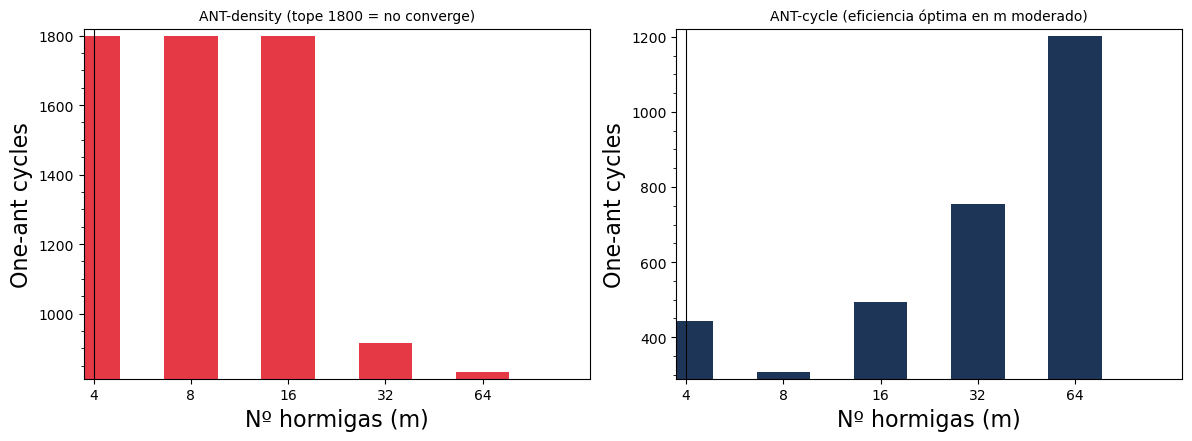

In [9]:
# ==============================================================================
# 8. EXPERIMENTO 3: RÉPLICA DE LAS FIGURAS 5 Y 8 (CUADRÍCULA 4x4)
# ==============================================================================

valores_m = [4, 8, 16, 32, 64]
N_REPS_M = 5
MAX_CICLOS_M = 200
VALOR_FALLO = 1800.0  # Valor tope visual cuando la mayoría de pruebas no llega al óptimo

def experimento_num_hormigas(variante):
    filas = [["m", "Éxitos (/5)", "Ciclos medios", "One-ant cycles (coste)"]]
    valores_barra = []

    for m in valores_m:
        ciclos_exito = []
        for rep in range(N_REPS_M):
            res = ejecutar_ant_system(
                coords_grid,
                variante=variante,
                n_hormigas=m,
                n_ciclos=MAX_CICLOS_M,
                alpha=1.0,
                beta=1.0,
                rho=0.7,
                Q=100.0,
                tau0=0.1,
                semilla=100 + rep,
                objetivo_optimo=16.0
            )
            if res["ciclo_optimo"] is not None:
                ciclos_exito.append(res["ciclo_optimo"])

        # Siguiendo el criterio del artículo: si la mayoría no alcanza el óptimo,
        # se asigna un valor alto por defecto ("Unable to reach optimum").
        if len(ciclos_exito) > N_REPS_M / 2.0:
            c_med = sum(ciclos_exito) / float(len(ciclos_exito))
            coste = c_med * m
            filas.append([m, f"{len(ciclos_exito)}/{N_REPS_M}", f"{c_med:.1f}", f"{coste:.1f}"])
            valores_barra.append(coste)
        else:
            filas.append([m, f"{len(ciclos_exito)}/{N_REPS_M}", ">200 (fallo)", "No alcanza óptimo"])
            valores_barra.append(VALOR_FALLO)

    return filas, valores_barra

print("=== ANT-density (réplica Fig. 5 del artículo) ===")
filas_den, barras_den = experimento_num_hormigas("ant-density")
show(table(filas_den, header_row=True, frame=True))

print("\n=== ANT-cycle (réplica Fig. 8 del artículo) ===")
filas_cyc, barras_cyc = experimento_num_hormigas("ant-cycle")
show(table(filas_cyc, header_row=True, frame=True))

etiquetas_m = [str(m) for m in valores_m]
b_den = bar_chart(
    barras_den, width=0.55, color='#e63946',
    ticks=[list(range(len(valores_m))), None],
    tick_formatter=[etiquetas_m, None],
    axes_labels=['Nº hormigas (m)', 'One-ant cycles'],
    frame=True,
    title='ANT-density (tope 1800 = no converge)'
)
b_cyc = bar_chart(
    barras_cyc, width=0.55, color='#1d3557',
    ticks=[list(range(len(valores_m))), None],
    tick_formatter=[etiquetas_m, None],
    axes_labels=['Nº hormigas (m)', 'One-ant cycles'],
    frame=True,
    title='ANT-cycle (eficiencia óptima en m moderado)'
)

graphics_array([b_den, b_cyc]).show(figsize=[12, 4.5])

---
## 9. Experimento 4: Rendimiento computacional y escalabilidad en SageMath
*(Correspondencia con la memoria: Sección 5)*

Analíticamente, en cada ciclo de `ANT-cycle`:
- Cada una de las $m$ hormigas recorre $n$ ciudades, y en cada paso evalúa como máximo $n$ candidatas $\implies O(m \cdot n^2)$.
- La actualización global de la matriz de feromonas recorre $n^2$ entradas $\implies O(n^2)$.

Por tanto, para $C$ ciclos la complejidad temporal teórica es **$O(C \cdot m \cdot n^2)$**. Si fijamos $m = n$ (una hormiga por ciudad), el tiempo de ejecución crece de forma **cúbica** con el tamaño del problema: **$O(C \cdot n^3)$**.

Comprobamos empíricamente ambos comportamientos en SageMath:
1. Crecimiento con $n \in \{10, 15, 20, 25, 30\}$ tomando $m = n$ ($C = 40$ ciclos).
2. Crecimiento lineal con la población $m \in \{5, 15, 30, 60\}$ manteniendo $n = 20$ fijo ($C = 40$ ciclos).

Escalabilidad al variar el tamaño del grafo n (m = n):


Ciudades (n),Hormigas (m=n),Ciclos,Tiempo (s)
,,,0.646
,,,3.748
,,,10.931
,,,25.229
,,,33.159



Escalabilidad al variar la población m (n = 20 fijo):


Hormigas (m),Ciudades (n=20),Ciclos,Tiempo (s)
,,,3.493
,,,8.043
,,,14.030
,,,28.757


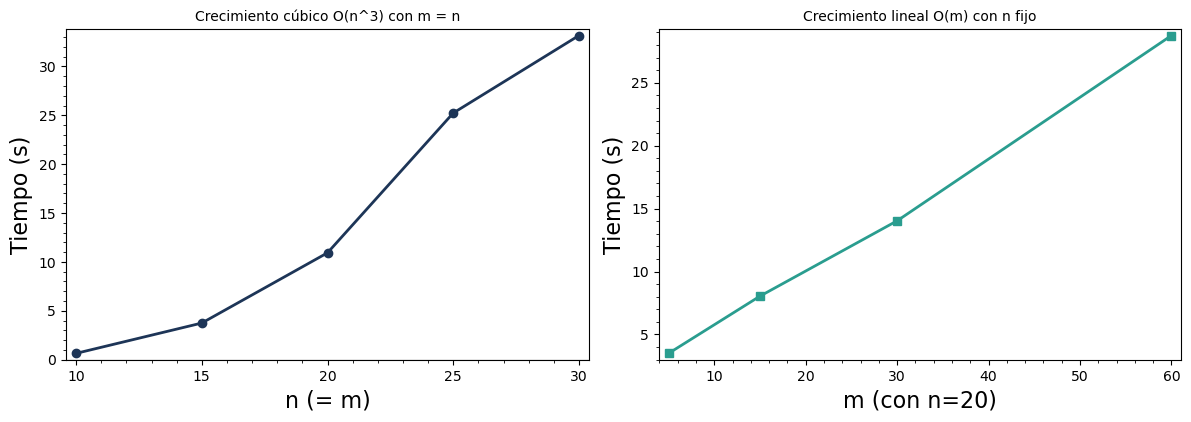

In [10]:
# ==============================================================================
# 9. EXPERIMENTO 4: RENDIMIENTO COMPUTACIONAL Y ESCALABILIDAD
# ==============================================================================

C_BENCH = 40

# 1) Escalado con n (con m = n -> complejidad esperada O(n^3))
ns = [10, 15, 20, 25, 30]
tiempos_n = []
filas_n = [["Ciudades (n)", "Hormigas (m=n)", "Ciclos", "Tiempo (s)"]]

for n_val in ns:
    c_rand = generar_grafo_aleatorio(n_val, semilla=99)
    res_t = ejecutar_ant_system(
        c_rand, variante="ant-cycle", n_hormigas=n_val, n_ciclos=C_BENCH,
        alpha=1.0, beta=5.0, rho=0.7, Q=100.0, semilla=99
    )
    tiempos_n.append((n_val, res_t["tiempo_s"]))
    filas_n.append([n_val, n_val, C_BENCH, f"{res_t['tiempo_s']:.3f}"])

# 2) Escalado con m (con n = 20 fijo -> complejidad esperada O(m) lineal)
ms = [5, 15, 30, 60]
tiempos_m = []
filas_m = [["Hormigas (m)", "Ciudades (n=20)", "Ciclos", "Tiempo (s)"]]
c_fijo = generar_grafo_aleatorio(20, semilla=99)

for m_val in ms:
    res_t = ejecutar_ant_system(
        c_fijo, variante="ant-cycle", n_hormigas=m_val, n_ciclos=C_BENCH,
        alpha=1.0, beta=5.0, rho=0.7, Q=100.0, semilla=99
    )
    tiempos_m.append((m_val, res_t["tiempo_s"]))
    filas_m.append([m_val, 20, C_BENCH, f"{res_t['tiempo_s']:.3f}"])

print("Escalabilidad al variar el tamaño del grafo n (m = n):")
show(table(filas_n, header_row=True, frame=True))
print("\nEscalabilidad al variar la población m (n = 20 fijo):")
show(table(filas_m, header_row=True, frame=True))

p_tn = list_plot(tiempos_n, plotjoined=True, marker='o', color='#1d3557', thickness=2,
                 frame=True, axes_labels=['n (= m)', 'Tiempo (s)'],
                 title='Crecimiento cúbico O(n^3) con m = n')
p_tm = list_plot(tiempos_m, plotjoined=True, marker='s', color='#2a9d8f', thickness=2,
                 frame=True, axes_labels=['m (con n=20)', 'Tiempo (s)'],
                 title='Crecimiento lineal O(m) con n fijo')

graphics_array([p_tn, p_tm]).show(figsize=[12, 4.3])

---
## 10. Extensiones propuestas y demostración interactiva
*(Correspondencia con la memoria: Sección 6 — Limitaciones y mejoras)*

Como cierre crítico, probamos directamente las **dos mejoras clásicas** planteadas en la memoria sobre `ANT-cycle`:
1. **Elitismo (`elitismo = 5`):** la mejor ruta global encontrada hasta el momento recibe un refuerzo adicional de feromona en cada ciclo, acelerando la explotación en torno a las mejores aristas.
2. **Hibridación con búsqueda local *2-opt* (`usar_2opt = True`):** elimina cruces locales en los recorridos construidos por las hormigas antes de actualizar la feromona.

Comprobaremos cómo esta versión híbrida alcanza el **óptimo exacto del artículo en Oliver30 ($423.741$ / entero $420$)** en apenas 40 ciclos, frente a los 4200 ciclos que necesitó la versión básica en la Fig. 6 del artículo original.

Algoritmo (Oliver30),Ciclos,Longitud real,Longitud entera,Tiempo (s)
ANT-cycle estándar (Sec. 6),,426.544,,44.28
ANT-cycle + Elitismo + 2-opt,,423.741,,28.97
"Referencia Fig. 6 (Colorni et al., 1991)",,423.741,,—


Primer ciclo en alcanzar el óptimo global (423.741 / 420): ciclo 1


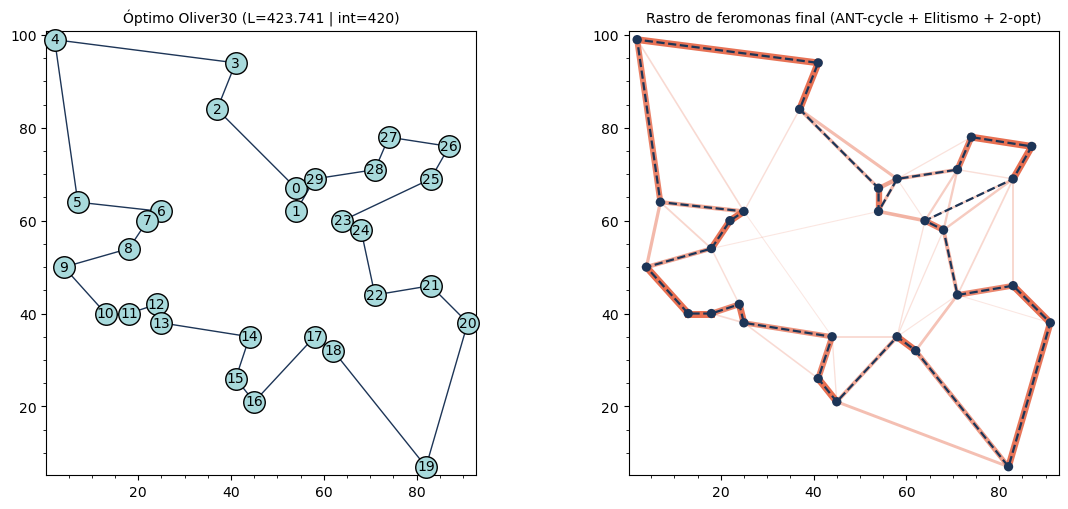

In [10]:
# ==============================================================================
# 10.1 COMPARATIVA EN OLIVER30: ANT-CYCLE ESTÁNDAR VS. ELITISMO + 2-OPT
# ==============================================================================

res_mejorado = ejecutar_ant_system(
    coords_o30,
    variante="ant-cycle",
    n_hormigas=30,
    n_ciclos=40,
    alpha=1.0,
    beta=5.0,
    rho=0.7,
    Q=100.0,
    tau0=0.1,
    semilla=42,
    elitismo=5.0,
    usar_2opt=True,
    objetivo_optimo=423.741
)

res_base = resultados_o30["ant-cycle"]
filas_comp = [
    ["Algoritmo (Oliver30)", "Ciclos", "Longitud real", "Longitud entera", "Tiempo (s)"],
    ["ANT-cycle estándar (Sec. 6)", N_CICLOS_O30, f"{res_base['mejor_longitud']:.3f}", res_base["mejor_longitud_entera"], f"{res_base['tiempo_s']:.2f}"],
    ["ANT-cycle + Elitismo + 2-opt", 40, f"{res_mejorado['mejor_longitud']:.3f}", res_mejorado["mejor_longitud_entera"], f"{res_mejorado['tiempo_s']:.2f}"],
    ["Referencia Fig. 6 (Colorni et al., 1991)", 4200, "423.741", 420, "—"]
]
show(table(filas_comp, header_row=True, frame=True))
print(f"Primer ciclo en alcanzar el óptimo global (423.741 / 420): ciclo {res_mejorado['ciclo_optimo']}")

p_opt_ruta = dibujar_ruta_grafo(
    coords_o30,
    res_mejorado["mejor_tour"],
    titulo=f"Óptimo Oliver30 (L={res_mejorado['mejor_longitud']:.3f} | int={res_mejorado['mejor_longitud_entera']})"
)
p_opt_fero = dibujar_mapa_feromonas(
    coords_o30,
    res_mejorado["tau_final"],
    titulo="Rastro de feromonas final (ANT-cycle + Elitismo + 2-opt)",
    tour_resaltado=res_mejorado["mejor_tour"],
    umbral_rel=0.05
)
graphics_array([p_opt_ruta, p_opt_fero]).show(figsize=[12, 5.2])

In [11]:
# ==============================================================================
# 10.2 LABORATORIO INTERACTIVO EN SAGEMATH (@interact)
# Ideal para responder preguntas en directo durante la presentación
# ==============================================================================

INSTANCIAS_DEMO = {
    "Cuadrícula 4x4 (16 ciudades, L*=16)": coords_grid,
    "10 ciudades (estilo Fig. 2)":         coords_10,
    "Oliver30 (30 ciudades, L*=423.741)":  coords_o30
}

@interact
def explorar_ant_system(
    instancia=selector(list(INSTANCIAS_DEMO.keys()), default="Cuadrícula 4x4 (16 ciudades, L*=16)", label="Instancia"),
    variante=selector(["ant-cycle", "ant-density", "ant-quantity"], default="ant-cycle", label="Variante"),
    alpha=slider(0.0, 5.0, 0.5, default=1.0, label="α (feromona)"),
    beta=slider(0.0, 10.0, 0.5, default=2.0, label="β (visibilidad)"),
    rho=slider(0.1, 0.95, 0.05, default=0.7, label="ρ (persistencia)"),
    n_ciclos=slider(10, 120, 10, default=50, label="Ciclos"),
    usar_2opt=checkbox(default=False, label="Activar mejora 2-opt")
):
    coords_sel = INSTANCIAS_DEMO[instancia]
    res = ejecutar_ant_system(
        coords_sel,
        variante=variante,
        n_hormigas=len(coords_sel),
        n_ciclos=int(n_ciclos),
        alpha=float(alpha),
        beta=float(beta),
        rho=float(rho),
        Q=100.0,
        tau0=0.1,
        semilla=42,
        usar_2opt=bool(usar_2opt)
    )
    print(f"[{variante}] Mejor longitud real: {res['mejor_longitud']:.3f} | "
          f"Entera: {res['mejor_longitud_entera']} | Tiempo: {res['tiempo_s']:.2f} s")

    p_f = dibujar_mapa_feromonas(
        coords_sel, res["tau_final"],
        titulo="Mapa final de feromonas",
        tour_resaltado=res["mejor_tour"],
        umbral_rel=0.05
    )
    p_c = list_plot(
        list(enumerate(res["hist_mejor_global"], start=1)),
        plotjoined=True, color='#1d3557', thickness=2.2,
        frame=True, axes_labels=['Ciclo', 'Mejor longitud'],
        title='Curva de convergencia'
    )
    graphics_array([p_f, p_c]).show(figsize=[11, 4.5])

Interactive function <function explorar_ant_system at 0x6ffdd5359680> with 7 widgets
  instancia: Dropdown(des…